# Data Description

King County covers Seattle and its surroundings. The data ships with this repository as **two tables**:

- `data/king_county_house_sales.csv`: one row per sale, with the date and the price
- `data/king_county_house_details.csv`: one row per house, with its physical attributes

`01_loading_the_data.ipynb` guides you through combining them into one table.

| Column | Table | Description |
| :-- | :-- | :-- |
| `date` | sales | date the house was sold |
| `price` | sales | sale price in dollars, the prediction target |
| `house_id` | sales | identifier of the house, matches `id` in the details table |
| `id` | sales | identifier of the sale |
| `id` | details | unique identifier for a house |
| `bedrooms` | details | number of bedrooms |
| `bathrooms` | details | number of bathrooms |
| `sqft_living` | details | square footage of the home |
| `sqft_lot` | details | square footage of the lot |
| `floors` | details | total floors (levels) in the house |
| `waterfront` | details | whether the house has a view to a waterfront |
| `view` | details | quality of the view |
| `condition` | details | overall condition of the house |
| `grade` | details | overall grade given to the housing unit, based on the King County grading system |
| `sqft_above` | details | square footage of the house apart from the basement |
| `sqft_basement` | details | square footage of the basement |
| `yr_built` | details | year the house was built |
| `yr_renovated` | details | year the house was renovated |
| `zipcode` | details | zip code |
| `lat` | details | latitude coordinate |
| `long` | details | longitude coordinate |
| `sqft_living15` | details | square footage of the interior living space of the nearest 15 neighbours |
| `sqft_lot15` | details | square footage of the land lots of the nearest 15 neighbours |

In [1]:
# Import the libraries you need for this project
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import loguniform
import plotly.express as px

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.linear_model import Ridge
from sklearn.dummy import DummyRegressor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

In [2]:
# Your code here
df = pd.read_csv("data/eda.csv")
df.head()

,date,price,house_id,id,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,2014-10-13,221900.0,7129300520,1,3.0,1.00,1180.0,5650.0,1.0,NaN,...,7,1180.0,0.0,1955,0.0,98178,47.5112,-122.257,1340.0,5650.0
1,2014-12-09,538000.0,6414100192,2,3.0,2.25,2570.0,7242.0,2.0,0.0,...,7,2170.0,400.0,1951,1991.0,98125,47.7210,-122.319,1690.0,7639.0
2,2015-02-25,180000.0,5631500400,3,2.0,1.00,770.0,10000.0,1.0,0.0,...,6,770.0,0.0,1933,NaN,98028,47.7379,-122.233,2720.0,8062.0
3,2014-12-09,604000.0,2487200875,4,4.0,3.00,1960.0,5000.0,1.0,0.0,...,7,1050.0,910.0,1965,0.0,98136,47.5208,-122.393,1360.0,5000.0
4,2015-02-18,510000.0,1954400510,5,3.0,2.00,1680.0,8080.0,1.0,0.0,...,8,1680.0,0.0,1987,0.0,98074,47.6168,-122.045,1800.0,7503.0


In [3]:
# Split train and test set
X = df.drop('price', axis=1)
y = df['price']

X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.2,
                                                    random_state=42)

X_train.shape, X_test.shape, y_train.shape, y_test.shape

((17277, 21), (4320, 21), (17277,), (4320,))

### EDA

In [4]:
# get a df with y and X for the EDA again 
df_train = pd.concat([X_train, y_train], axis=1)
df_train.head()

,date,house_id,id,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15,price
6243,2014-12-22,9834201100,6244,4.0,2.00,1440.0,4855.0,2.0,0.0,0.0,...,1440.0,0.0,1972,0.0,98144,47.5717,-122.287,1300.0,4080.0,332500.0
8986,2015-05-12,7795810110,8987,3.0,1.75,1430.0,9857.0,1.0,0.0,2.0,...,1140.0,290.0,1980,0.0,98045,47.4964,-121.771,1310.0,9880.0,390000.0
9419,2014-12-29,1853081250,9420,4.0,2.75,3120.0,5000.0,2.0,0.0,0.0,...,3120.0,0.0,2010,0.0,98074,47.5940,-122.062,3200.0,5000.0,800000.0
10155,2015-03-21,2558630350,10156,4.0,2.50,2060.0,6958.0,1.0,0.0,0.0,...,1220.0,840.0,1974,NaN,98034,47.7251,-122.168,1760.0,7350.0,462000.0
10436,2014-07-01,3362401000,10437,3.0,2.00,2500.0,4080.0,1.5,0.0,0.0,...,1680.0,820.0,1922,0.0,98103,47.6813,-122.346,1550.0,3060.0,695000.0


In [5]:
df_train.view.unique()

array([ 0.,  2.,  3., nan,  4.,  1.])

In [6]:
df_train.condition.unique()

array([4, 3, 5, 2, 1])

In [7]:
df_train.grade.unique()

array([ 7,  9,  8, 11,  6, 10, 13,  5, 12,  4,  3])

In [8]:
df_train.sqft_basement.value_counts(dropna=False)

sqft_basement
0.0       10249
NaN         356
600.0       174
500.0       168
800.0       159
          ...  
1548.0        1
2600.0        1
295.0         1
1610.0        1
176.0         1
Name: count, Length: 286, dtype: int64

In [9]:
df_train.isna().sum()

date                0
house_id            0
id                  0
bedrooms            0
bathrooms           0
sqft_living         0
sqft_lot            0
floors              0
waterfront       1907
view               53
condition           0
grade               0
sqft_above          0
sqft_basement     356
yr_built            0
yr_renovated     3069
zipcode             0
lat                 0
long                0
sqft_living15       0
sqft_lot15          0
price               0
dtype: int64

In [10]:
df_train.info()

<class 'pandas.DataFrame'>
Index: 17277 entries, 6243 to 15795
Data columns (total 22 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           17277 non-null  str    
 1   house_id       17277 non-null  int64  
 2   id             17277 non-null  int64  
 3   bedrooms       17277 non-null  float64
 4   bathrooms      17277 non-null  float64
 5   sqft_living    17277 non-null  float64
 6   sqft_lot       17277 non-null  float64
 7   floors         17277 non-null  float64
 8   waterfront     15370 non-null  float64
 9   view           17224 non-null  float64
 10  condition      17277 non-null  int64  
 11  grade          17277 non-null  int64  
 12  sqft_above     17277 non-null  float64
 13  sqft_basement  16921 non-null  float64
 14  yr_built       17277 non-null  int64  
 15  yr_renovated   14208 non-null  float64
 16  zipcode        17277 non-null  int64  
 17  lat            17277 non-null  float64
 18  long           1727

In [11]:
# a lot of the data formats are not correct yet
# zipcode should be a string
# house_id and id should be a string 
# waterfront should be a bool - also has quite a few missings -> onehotencode this as a feature
# view is the quality of view, so we need to make this an ordinal feature later on - also has missings
# condition is also supposed to be ordinal, scale from 1-5 
# probably the same for grade, ordinal too
# sqft_basement has quite a few missings, maybe those dont have any basement? but theres also 0 values..

# yr_renovated definitely needs to be a int instead of a float
# yr_built and yr_renovated are intesting columns but maybe the age of the house and the years since last renovation would be the more interesting features
# -> should probably create those from scratch and then drop the columns yr_built and yr_renovated
# and then we'll see whether keeping those as a numeric feature or binning them is the better choice
# I would make this choice depending on the range of values we get. 

In [12]:
px.histogram(df_train, 
             x='price')

In [13]:
df_train.price.describe()

count    1.727700e+04
mean     5.415190e+05
std      3.689687e+05
min      7.800000e+04
25%      3.240000e+05
50%      4.500000e+05
75%      6.455000e+05
max      7.700000e+06
Name: price, dtype: float64

In [14]:
px.box(df_train, 
       y='price')

> We have a huge range of the price here, starting at a min of 78k up until 1.12M, the distribution is also quite skewed

In [15]:
print("mean vs median:", df["price"].mean(), df["price"].median())

mean vs median: 540296.5735055795 450000.0


> The huge difference between mean and median do support this guess as well

In [16]:
df_train["price"].skew()

np.float64(3.9517741921372576)

> Values at around 0 indicate a symmetric distribution, the price is at almost 4 -> very skewed! We definitely need to use the log on our target variable. 

In [17]:
px.histogram(df_train,
        x=np.log(df_train['price']))

> After using the log, the distribution of our target variable would a lot better

In [18]:
df_train['date'] = pd.to_datetime(df_train['date'])
df_train['house_id'] = df_train['house_id'].astype(str)
df_train['id'] = df_train['id'].astype(str)
df_train['zipcode'] = df_train['zipcode'].astype(str)

df_train.info()

<class 'pandas.DataFrame'>
Index: 17277 entries, 6243 to 15795
Data columns (total 22 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   date           17277 non-null  datetime64[us]
 1   house_id       17277 non-null  str           
 2   id             17277 non-null  str           
 3   bedrooms       17277 non-null  float64       
 4   bathrooms      17277 non-null  float64       
 5   sqft_living    17277 non-null  float64       
 6   sqft_lot       17277 non-null  float64       
 7   floors         17277 non-null  float64       
 8   waterfront     15370 non-null  float64       
 9   view           17224 non-null  float64       
 10  condition      17277 non-null  int64         
 11  grade          17277 non-null  int64         
 12  sqft_above     17277 non-null  float64       
 13  sqft_basement  16921 non-null  float64       
 14  yr_built       17277 non-null  int64         
 15  yr_renovated   14208 non-null  f

### check correlations with target

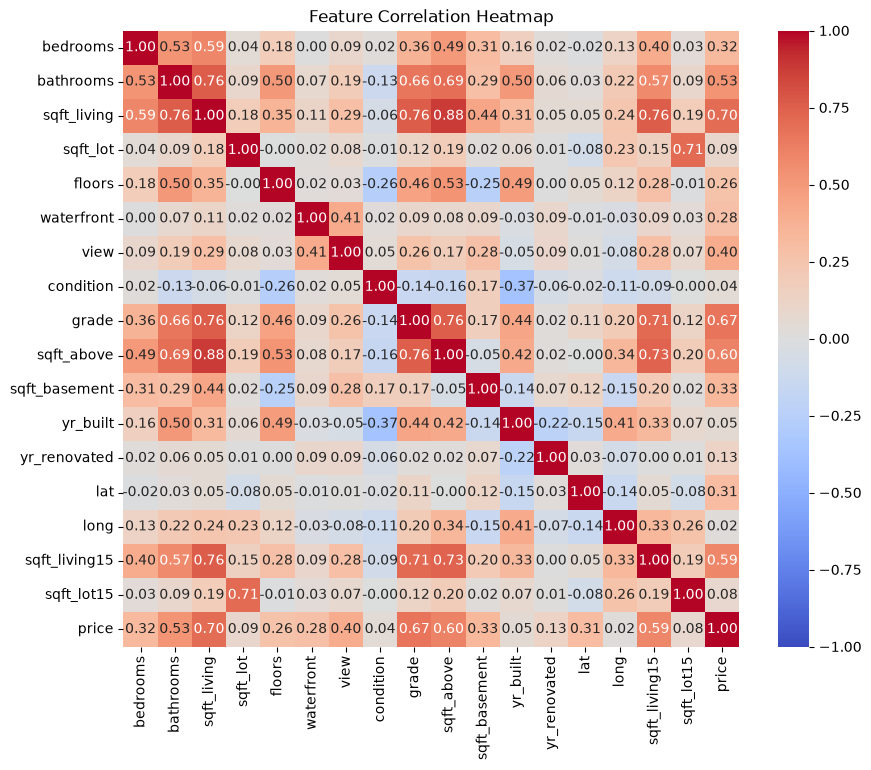

In [19]:
# Linear (Pearson) correlations between all numeric features
corr = df_train.corr(numeric_only=True)

# Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0, square=True)
plt.title("Feature Correlation Heatmap")
plt.show()

In [20]:
# sort by correlation with target variable price 
corr['price'].sort_values(ascending=False)

price            1.000000
sqft_living      0.701778
grade            0.670040
sqft_above       0.603072
sqft_living15    0.588622
bathrooms        0.529378
view             0.400145
sqft_basement    0.330814
bedrooms         0.315422
lat              0.305863
waterfront       0.275487
floors           0.258561
yr_renovated     0.128924
sqft_lot         0.089524
sqft_lot15       0.078741
yr_built         0.047772
condition        0.042909
long             0.017225
Name: price, dtype: float64

> There are quite a few features with medium to high positive linear correlation with the target 'price'

### Check for multicollinearity

In [29]:
# Features only (no target), numeric columns, no NaNs
X_only_numeric = df_train.drop(columns="price").select_dtypes("number").dropna()

# Add a constant so the VIFs are computed with an intercept
X_const = add_constant(X_only_numeric)

vif = pd.DataFrame({
    "feature": X_const.columns,
    "VIF": [variance_inflation_factor(X_const.values, i) for i in range(X_const.shape[1])]
}).query("feature != 'const'").sort_values("VIF", ascending=False)

print(vif)


          feature           VIF
3     sqft_living  1.000800e+15
11  sqft_basement  1.000800e+15
10     sqft_above  1.000800e+15
9           grade  3.424072e+00
2       bathrooms  3.387457e+00
16  sqft_living15  2.979416e+00
12       yr_built  2.382747e+00
17     sqft_lot15  2.067992e+00
4        sqft_lot  2.044203e+00
5          floors  2.001494e+00
1        bedrooms  1.694441e+00
15           long  1.505057e+00
7            view  1.413179e+00
8       condition  1.244062e+00
6      waterfront  1.205942e+00
13   yr_renovated  1.143743e+00
14            lat  1.126007e+00


/var/folders/t1/mlhpn4w94rn3zvlmgck2f_jh0000gn/T/ipykernel_89697/2911380456.py:9: UserWarning: The design matrix is poorly conditioned (condition number=9.15e+15). VIF calculations may be numerically unstable.
  "VIF": [variance_inflation_factor(X_const.values, i) for i in range(X_const.shape[1])]
/Users/khaldouna/Documents/Neuefische/w3d5/amle-project-king-county/.venv/lib/python3.13/site-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/Users/khaldouna/Documents/Neuefische/w3d5/amle-project-king-county/.venv/lib/python3.13/site-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/Users/khaldouna/Documents/Neuefische/w3d5/amle-project-king-county/.venv/lib/python3.13/site-packages/

In [30]:
check = df_train[["sqft_living", "sqft_above", "sqft_basement"]].dropna()

diff = check["sqft_living"] - (check["sqft_above"] + check["sqft_basement"])

print("rows checked:", len(check))
print("rows where that calculation is correct:", (diff == 0).sum())
print("rows where it doesn't:", (diff != 0).sum())

rows checked: 16921
rows where that calculation is correct: 16921
rows where it doesn't: 0


> So when checking for multicollinearity we get all these warnings because sqft_living = sqft_basement + sqft_above basically. So we can probably drop sqft_living and get rid of a lot of multicollinearity that way. 

In [31]:
# Features only (no target), numeric columns, no NaNs
X_only_numeric = df_train.drop(columns=["price", "sqft_living"]).select_dtypes("number").dropna()

# Add a constant so the VIFs are computed with an intercept
X_const = add_constant(X_only_numeric)

vif = pd.DataFrame({
    "feature": X_const.columns,
    "VIF": [variance_inflation_factor(X_const.values, i) for i in range(X_const.shape[1])]
}).query("feature != 'const'").sort_values("VIF", ascending=False)

print(vif)


          feature       VIF
9      sqft_above  5.009595
8           grade  3.424072
2       bathrooms  3.387457
15  sqft_living15  2.979416
11       yr_built  2.382747
16     sqft_lot15  2.067992
3        sqft_lot  2.044203
10  sqft_basement  2.023172
4          floors  2.001494
1        bedrooms  1.694441
14           long  1.505057
6            view  1.413179
7       condition  1.244062
5      waterfront  1.205942
12   yr_renovated  1.143743
13            lat  1.126007


> This looks a lot better. So we definitely need to drop sqft_living
> we still have a value of 5 for sqft_above but I think we'll leave it at that for now

### Boxplots for categorical variables

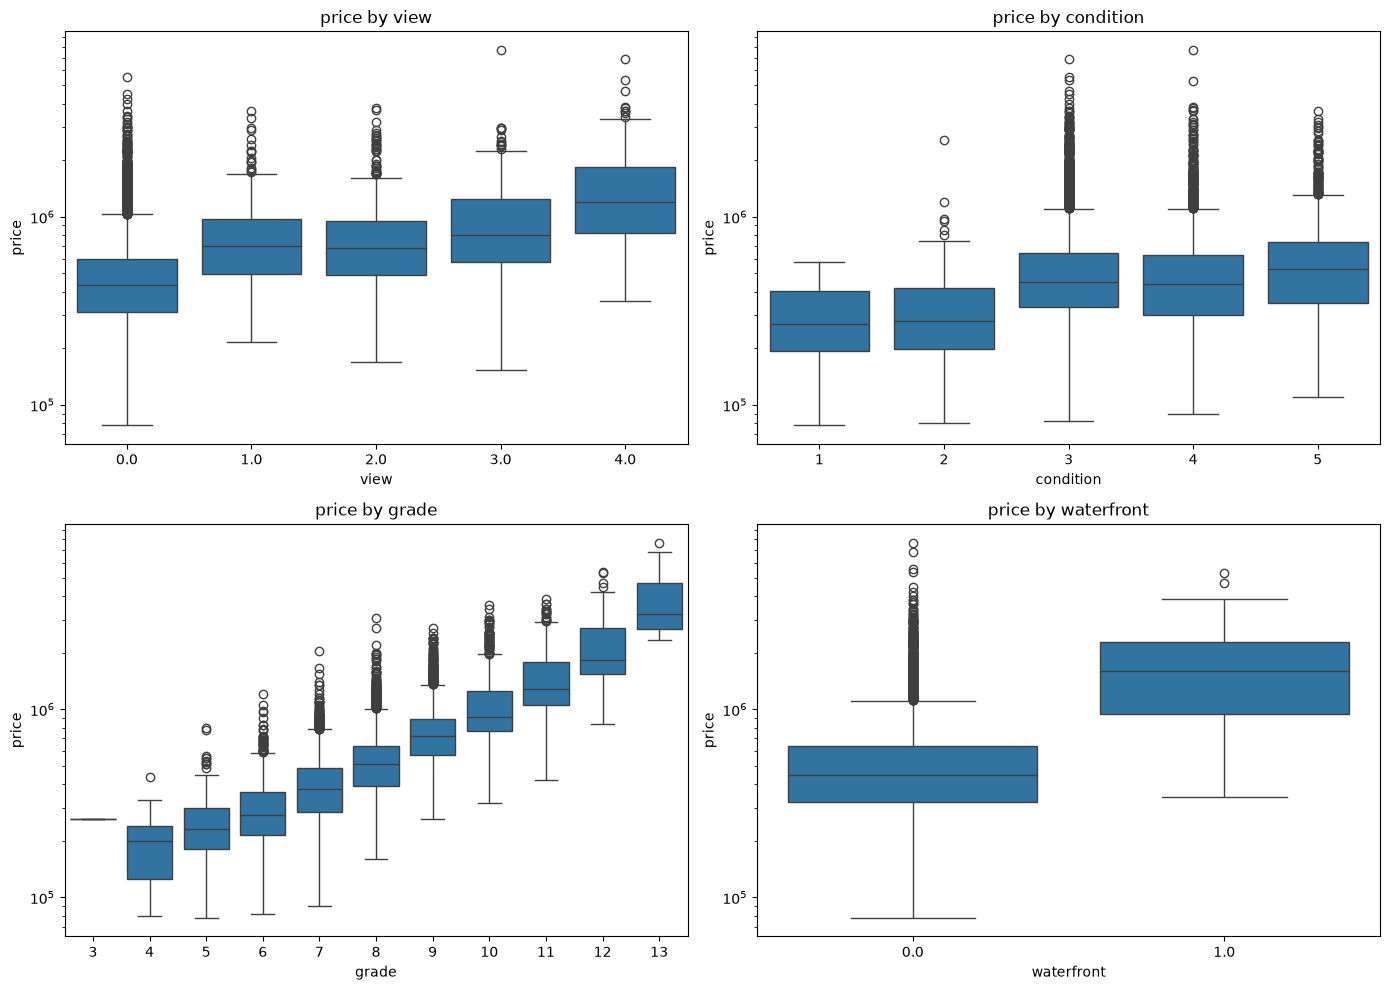

In [32]:
cat_cols = ["view", "condition", "grade", "waterfront"]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, col in zip(axes.flat, cat_cols):
    sns.boxplot(data=df_train, x=col, y="price", ax=ax)
    ax.set_title(f"price by {col}")
    ax.set_yscale("log")   # price is skewed, log scale makes the boxes readable

plt.tight_layout()
plt.show()


> The higher the view, the more a house gets sold for. view 1 and 2 as well as 3 have houses with pretty much the same prices 

> Houses in better condition also tend to cost more money but it kind of comes to an halt after condition 3 -> so if the house has a condition of higher than 3, it doesnt push the sale price much more on average 

> The better the grade, the higher the price of a sold house, this is pretty clear! 

> Also houses with a waterfront view tend to be sold for more money 


### scatterplots with target

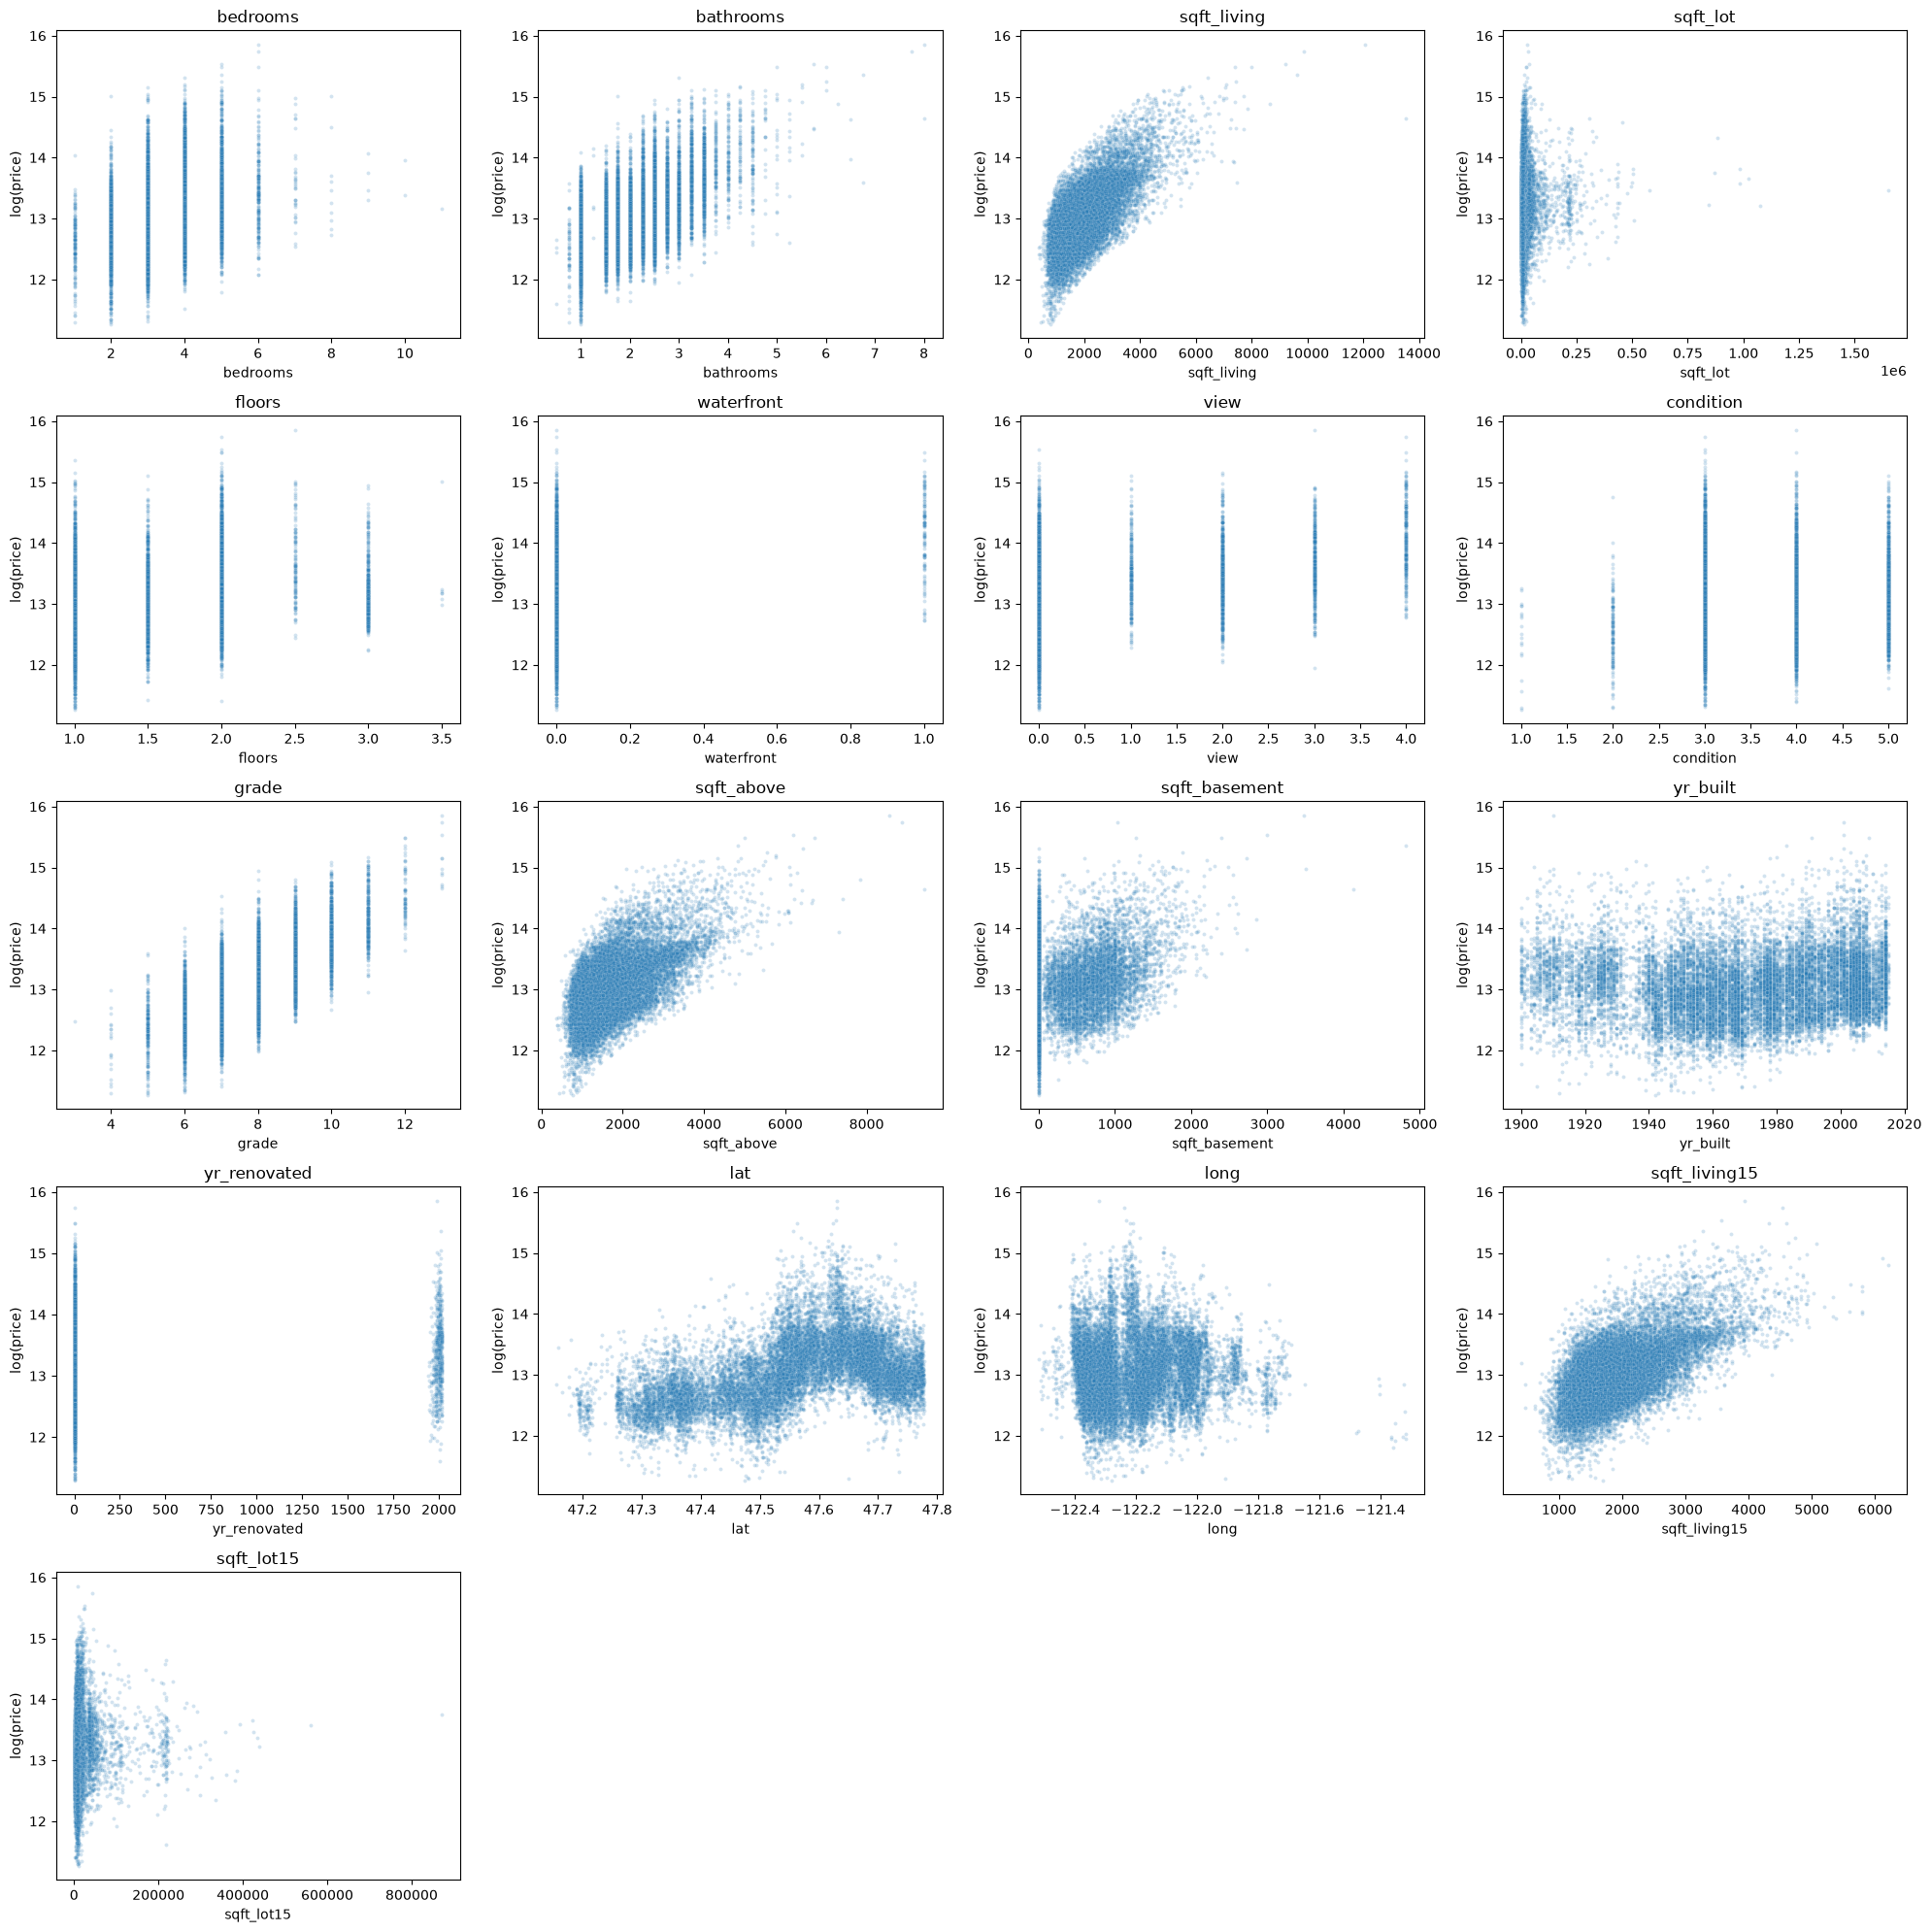

In [33]:
num_cols = (
    df_train.drop(columns="price")
    .select_dtypes("number")
    .columns
)

n_cols = 4
n_rows = int(np.ceil(len(num_cols) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows))

for ax, col in zip(axes.flat, num_cols):
    sns.scatterplot(
        x=df_train[col], y=np.log(df_train["price"]),
        alpha=0.2, s=8, ax=ax
    )
    ax.set_title(col)
    ax.set_ylabel("log(price)")

# hide unused axes in the last row
for ax in axes.flat[len(num_cols):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()


> This again shows us that grade, number of bathrooms and bedrooms, sqft above, sqft basement and sqft living15 could be interesting features for our model.

> We also see that sqft_lot, sqft_lot15 and sqft_living (which we are dropping later on) are right-skewed

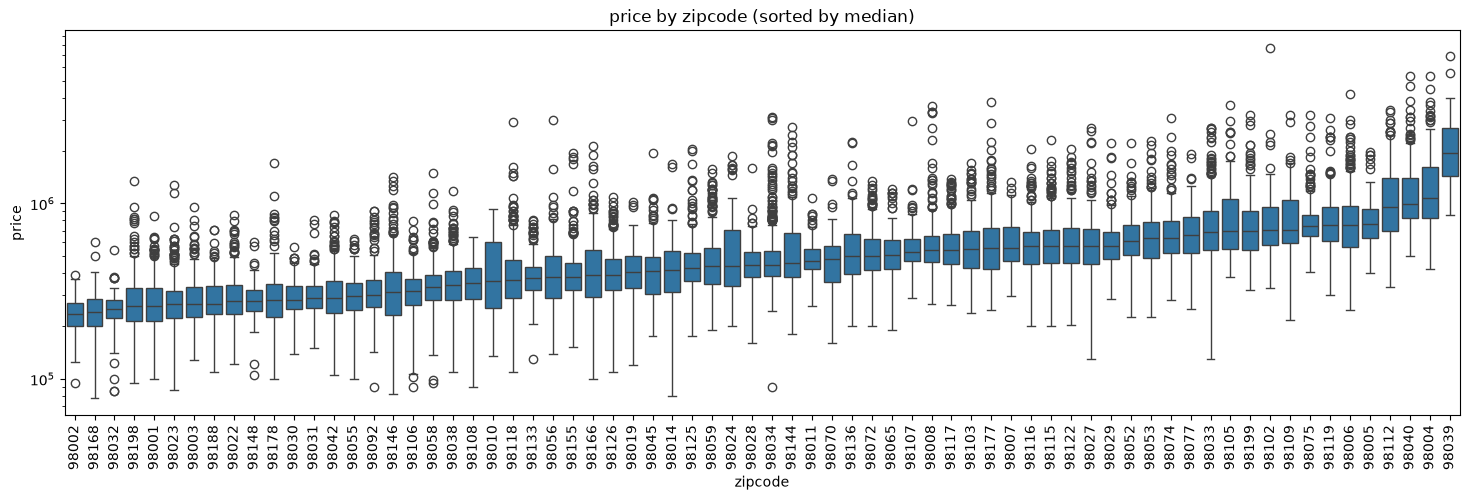

In [34]:
# zipcode gets its own plot because theres so many values inside of it
# sort by median price
order = df_train.groupby("zipcode")["price"].median().sort_values().index

plt.figure(figsize=(18, 5))
sns.boxplot(data=df_train, x="zipcode", y="price", order=order)
plt.yscale("log")
plt.xticks(rotation=90)
plt.title("price by zipcode (sorted by median)")
plt.show()


## Features to consider

> Use log on target variable - important! 

### Drop columns 
> drop sqft_living since it is the result of sqft_above + sqft_basement and we would have multicollinearity if keeping it plus redundant information

### Format data correctly
> date format -> date 
> zipcode should be a string
> house_id should be a string 
> id should be a string 

### Impute Missings 
>waterfront 
>view 
>sqft_basement has quite a few missings, maybe those dont have any basement? but theres also 0 values..

### Ordinal 
> waterfront should be a bool - also has quite a few missings -> onehotencode this as a feature
> view is the quality of view, so we need to make this an ordinal feature later on - also has missings
> condition is also supposed to be ordinal, scale from 1-5 
> probably the same for grade, ordinal too

### Create new features by hand 
>yr_renovated definitely needs to be a int instead of a float
yr_built and yr_renovated are intesting columns but maybe the age of the house and the years since last renovation would be the more interesting features
-> should probably create those from scratch and then drop the columns yr_built and yr_renovated
and then we'll see whether keeping those as a numeric feature or binning them is the better choice
I would make this choice depending on the range of values we get. 

>date (date sold) maybe split this feature into year sold, month sold, probably dont need the date day 

### Keep features with a high correlation with target variable 
> Probably at least these:
> sqft_living      0.701778
> grade            0.670040
> sqft_above       0.603072
> sqft_living15    0.588622
> bathrooms        0.529378
> view             0.400145
> sqft_basement    0.330814
> bedrooms         0.315422
> lat              0.305863
> waterfront       0.275487
> floors           0.258561 